In [1]:
# Day 33: Model Comparison

print("Day 33 - Model Comparison and Evaluation")
print("Project: Smart House Price Predictor")

Day 33 - Model Comparison and Evaluation
Project: Smart House Price Predictor


In [2]:
import pandas as pd

data = {
    "area_sqft": [800, 1000, 1200, 1500, 1800, 2000,
                  2200, 2500, 900, 1300, 1600, 2100,
                  1100, 1700, 2300, 1400],
    "bedrooms":  [2, 2, 3, 3, 3, 4, 4, 4, 2, 3, 3, 4,
                  2, 3, 4, 3],
    "bathrooms": [1, 2, 2, 2, 3, 3, 3, 4, 1, 2, 2, 3,
                  2, 2, 3, 2],
    "parking":   [0, 1, 1, 1, 1, 2, 2, 2, 0, 1, 1, 2,
                  1, 1, 2, 1],
    "price":     [2000000, 2500000, 3200000, 4000000,
                  4800000, 5500000, 6200000, 7500000,
                  2200000, 3300000, 4200000, 6000000,
                  2800000, 4500000, 6800000, 3700000]
}

df = pd.DataFrame(data)
display(df.head())
print("Dataset created successfully!")

,area_sqft,bedrooms,bathrooms,parking,price
0,800,2,1,0,2000000
1,1000,2,2,1,2500000
2,1200,3,2,1,3200000
3,1500,3,2,1,4000000
4,1800,3,3,1,4800000


Dataset created successfully!


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

X = df[["area_sqft", "bedrooms", "bathrooms", "parking"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

linear_model = LinearRegression()
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)

linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

print("Both models trained successfully!")

Both models trained successfully!


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, predictions in [
    ("Linear Regression", linear_predictions),
    ("Decision Tree", tree_predictions)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,MAE,MSE,R2 Score
0,Linear Regression,184166.667,4.479969e+10,0.989
1,Decision Tree,475000.000,2.525000e+11,0.938


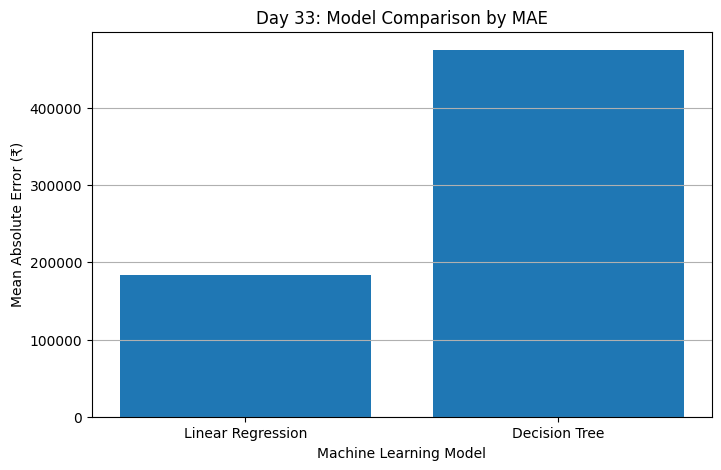

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("Day 33: Model Comparison by MAE")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error (₹)")
plt.grid(axis="y")
plt.show()

In [6]:
results_df.to_csv("day33_model_comparison.csv", index=False)

print("Comparison results saved successfully!")

Comparison results saved successfully!


# Day 33 - Model Comparison and Evaluation

## Work Completed
- Created a sample house price dataset.
- Split the data into training and testing sets.
- Trained Linear Regression and Decision Tree models.
- Compared MAE, MSE, and R² scores.
- Created a model comparison graph.
- Saved the results as a CSV file.

## Conclusion
Model comparison helps identify which model performs better on the test dataset. Lower MAE and MSE generally indicate smaller errors, while a higher R² can indicate a better fit. Results depend on the dataset and should be verified with more real-world data.